# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('Data/AviationData_Cleaned.csv', parse_dates=['Event.Date'])

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [6]:
# Small airplanes: fewer than 20 people on board
small = df[df['Total.Passengers'] <= 20]

# Large airplanes: 20 or more people on board
large = df[df['Total.Passengers'] > 20]

print(len(small_df), len(large_df))

56598 655


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [9]:
# Small airplanes: mean fatal/serious injury fraction and number of events per make
small_make = small.groupby("Make")["Fatal.Serious.Fraction"].agg(["mean", "count"])
top15_small = small_make.sort_values("mean").head(15)

# Large airplanes: same computation
large_make = large.groupby("Make")["Fatal.Serious.Fraction"].agg(["mean", "count"])
top15_large = large_make.sort_values("mean").head(15)

# Display results (count is kept to judge how reliable each mean is)
print("Small makes - lowest mean fatal/serious fraction:")
print(top15_small)
print("\nLarge makes - lowest mean fatal/serious fraction:")
print(top15_large)

Small makes - lowest mean fatal/serious fraction:
                        mean  count
Make                               
WACO                0.103406    137
BOMBARDIER          0.127086     21
HELIO               0.133642    103
MAULE               0.153821    567
GREAT LAKES         0.163793     58
AVIAT AIRCRAFT INC  0.164474     76
SCHWEIZER           0.177358    265
WEATHERLY           0.178571     84
BOEING              0.179845    444
BOEING STEARMAN     0.180000     50
STINSON             0.199561    418
SWEARINGEN          0.200958    118
GRUMMAN             0.209557   1496
AVIAT               0.210145    138
MCDONNELL DOUGLAS   0.213310     61

Large makes - lowest mean fatal/serious fraction:
                       mean  count
Make                              
AERO COMMANDER     0.000000      1
GULFSTREAM         0.000000      1
SWEARINGEN         0.000000      1
CESSNA             0.008150      5
MCDONNELL DOUGLAS  0.062233    102
BOMBARDIER         0.081918     42
LEARJET

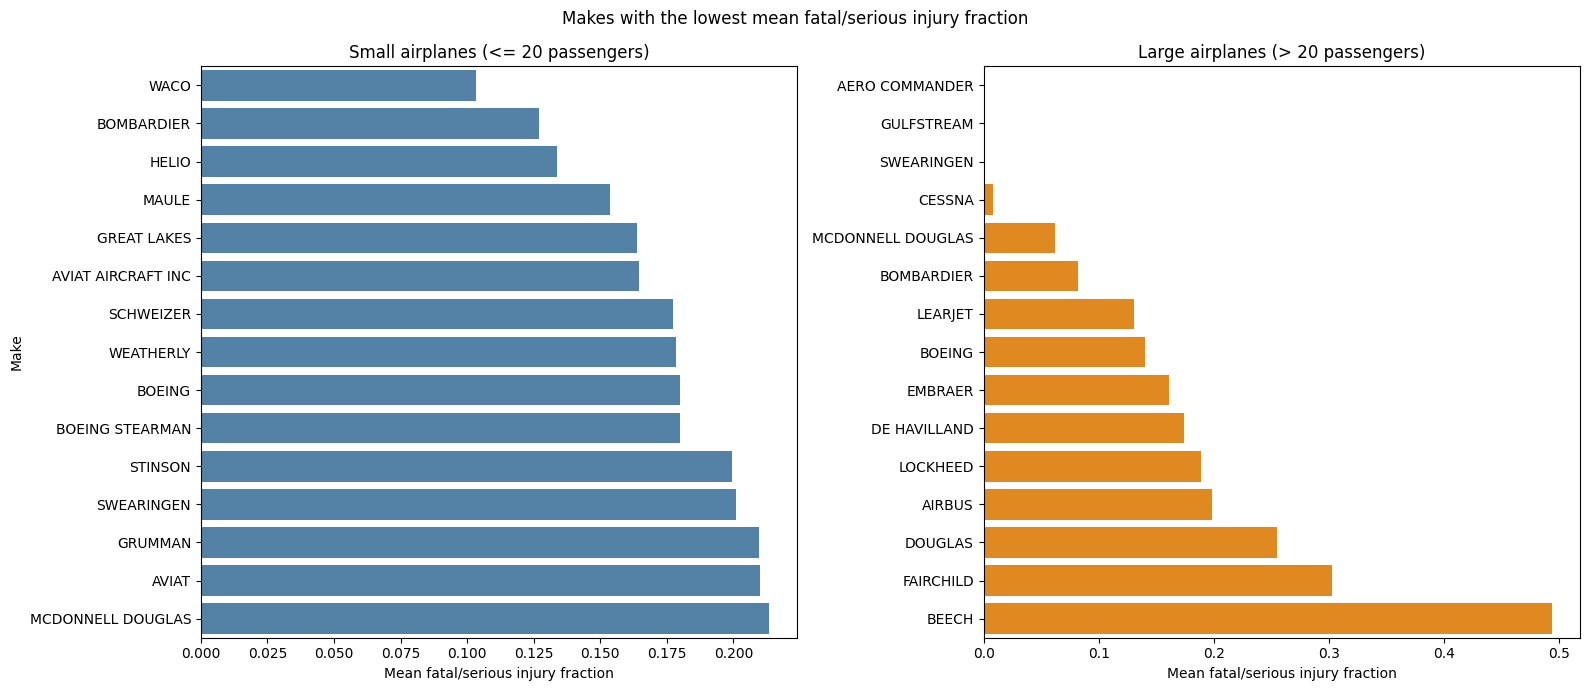

In [10]:
# Side-by-side bar plots of the mean fatal/serious injury fraction
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Small airplanes
sns.barplot(x=top15_small["mean"], y=top15_small.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small airplanes (<= 20 passengers)")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[0].set_ylabel("Make")

# Large airplanes
sns.barplot(x=top15_large["mean"], y=top15_large.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large airplanes (> 20 passengers)")
axes[1].set_xlabel("Mean fatal/serious injury fraction")
axes[1].set_ylabel("")

plt.suptitle("Makes with the lowest mean fatal/serious injury fraction")
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

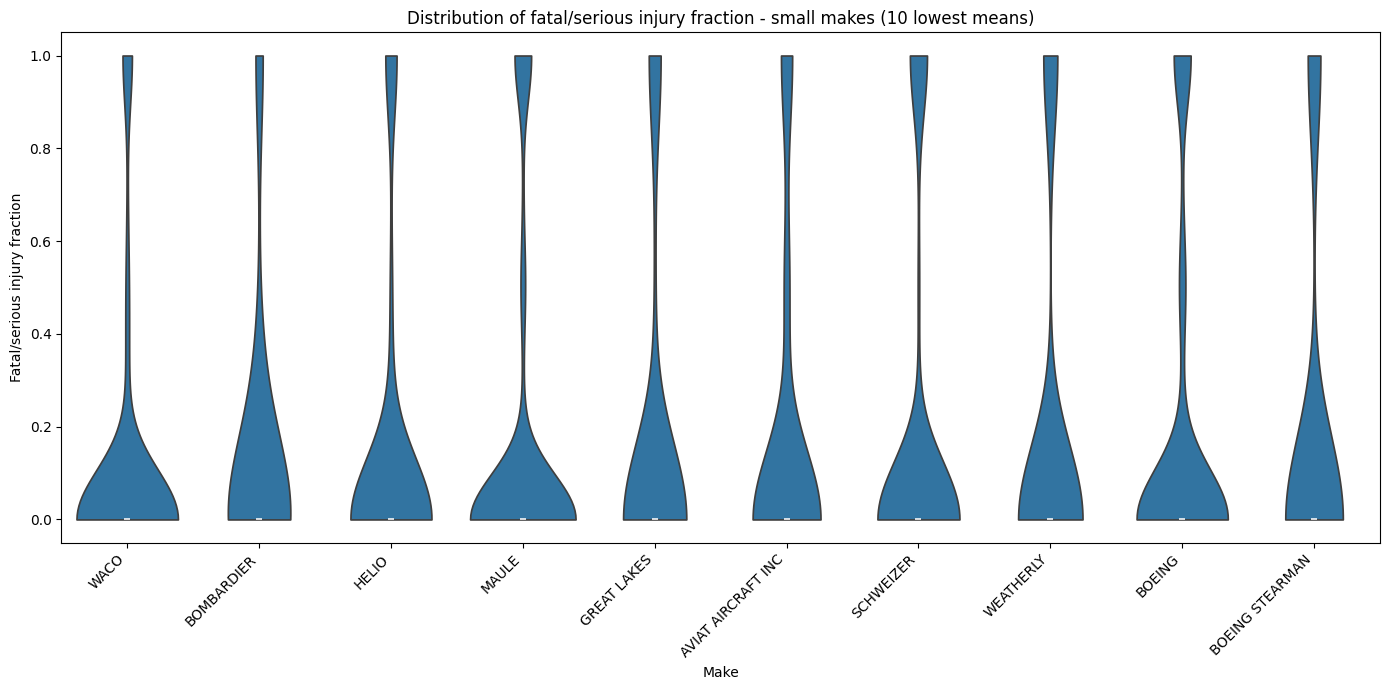

In [11]:
# Select the 10 small makes with the lowest mean fatal/serious injury fraction
top10_small = small_make.sort_values("mean").head(10).index

# Keep only the events for these 10 makes
small_top10_data = small[small["Make"].isin(top10_small)]

# Violin plot of the distribution of the fatal/serious injury fraction
plt.figure(figsize=(14, 7))
sns.violinplot(
    data=small_top10_data,
    x="Make",
    y="Fatal.Serious.Fraction",
    order=top10_small,   # keep makes sorted from lowest to highest mean
    cut=0                # do not extend the violins beyond the real data range (0 to 1)
)
plt.title("Distribution of fatal/serious injury fraction - small makes (10 lowest means)")
plt.xlabel("Make")
plt.ylabel("Fatal/serious injury fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

                       mean  count
Make                              
AERO COMMANDER     0.000000      1
GULFSTREAM         0.000000      1
SWEARINGEN         0.000000      1
CESSNA             0.008150      5
MCDONNELL DOUGLAS  0.062233    102
BOMBARDIER         0.081918     42
LEARJET            0.130435      1
BOEING             0.140120    316
EMBRAER            0.161418     46
DE HAVILLAND       0.173990     19


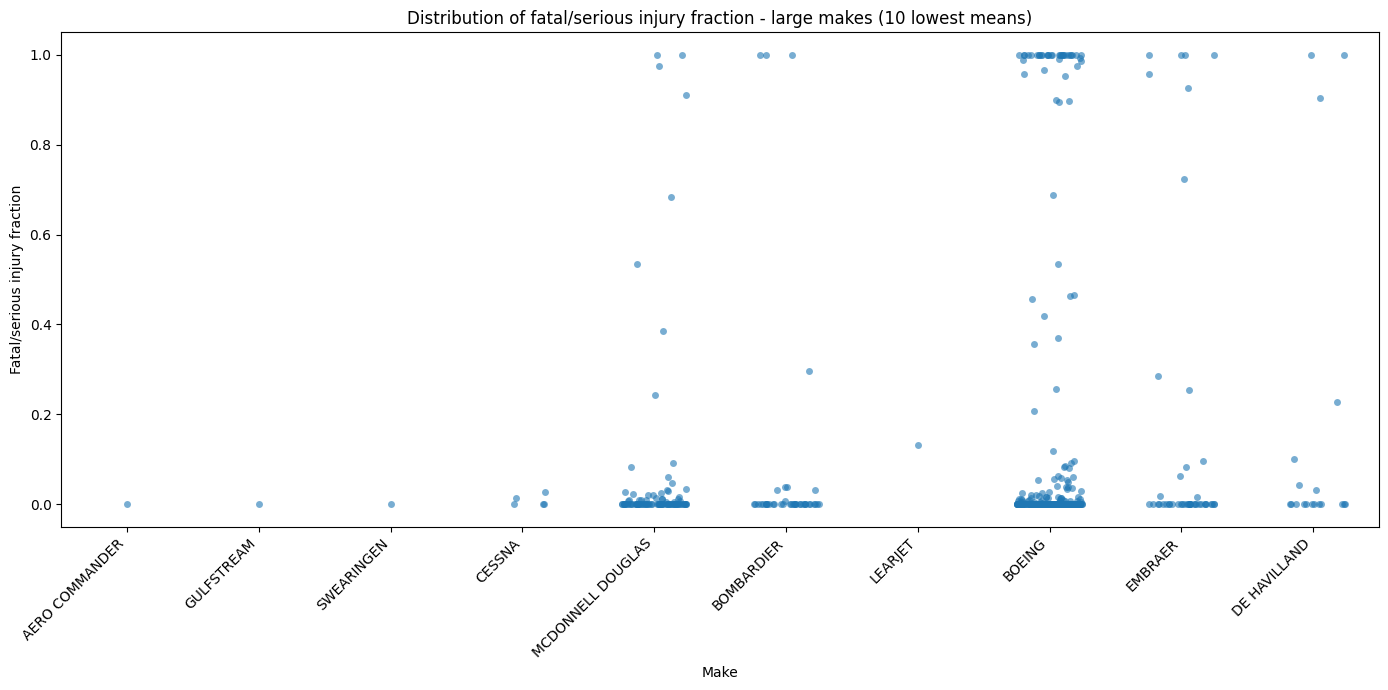

In [12]:
#Select the 10 large makes with the lowest mean fatal/serious injury fraction
top10_large = large_make.sort_values("mean").head(10).index

# Show the mean and number of events per make, to judge how reliable each mean is
print(large_make.sort_values("mean").head(10))

# Keep only the events for these 10 makes
large_top10_data = large[large["Make"].isin(top10_large)]

# Strip plot: each dot is one accident
plt.figure(figsize=(14, 7))
sns.stripplot(
    data=large_top10_data,
    x="Make",
    y="Fatal.Serious.Fraction",
    order=top10_large,   # keep makes sorted from lowest to highest mean
    jitter=0.25,         # spread the dots horizontally so they do not overlap
    alpha=0.6            # transparency to see dense areas
)
plt.title("Distribution of fatal/serious injury fraction - large makes (10 lowest means)")
plt.xlabel("Make")
plt.ylabel("Fatal/serious injury fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

Small makes - lowest destruction rate:
                                mean  count
Make                                       
AMERICAN CHAMPION AIRCRAFT  0.037736     53
AVIAT AIRCRAFT INC          0.039474     76
DIAMOND                     0.076023    171
AVIAT                       0.086957    138
WACO                        0.087591    137
MAULE                       0.093474    567
ERCOUPE                     0.094595     74
BOMBARDIER                  0.095238     21
BOEING STEARMAN             0.100000     50
LUSCOMBE                    0.103896    385
TAYLORCRAFT                 0.123967    363
HELIO                       0.126214    103
STINSON                     0.133971    418
AERONCA                     0.137645    603
GREAT LAKES                 0.137931     58

Large makes - lowest destruction rate:
                       mean  count
Make                              
AERO COMMANDER     0.000000      1
GULFSTREAM         0.000000      1
SWEARINGEN         0.000000      

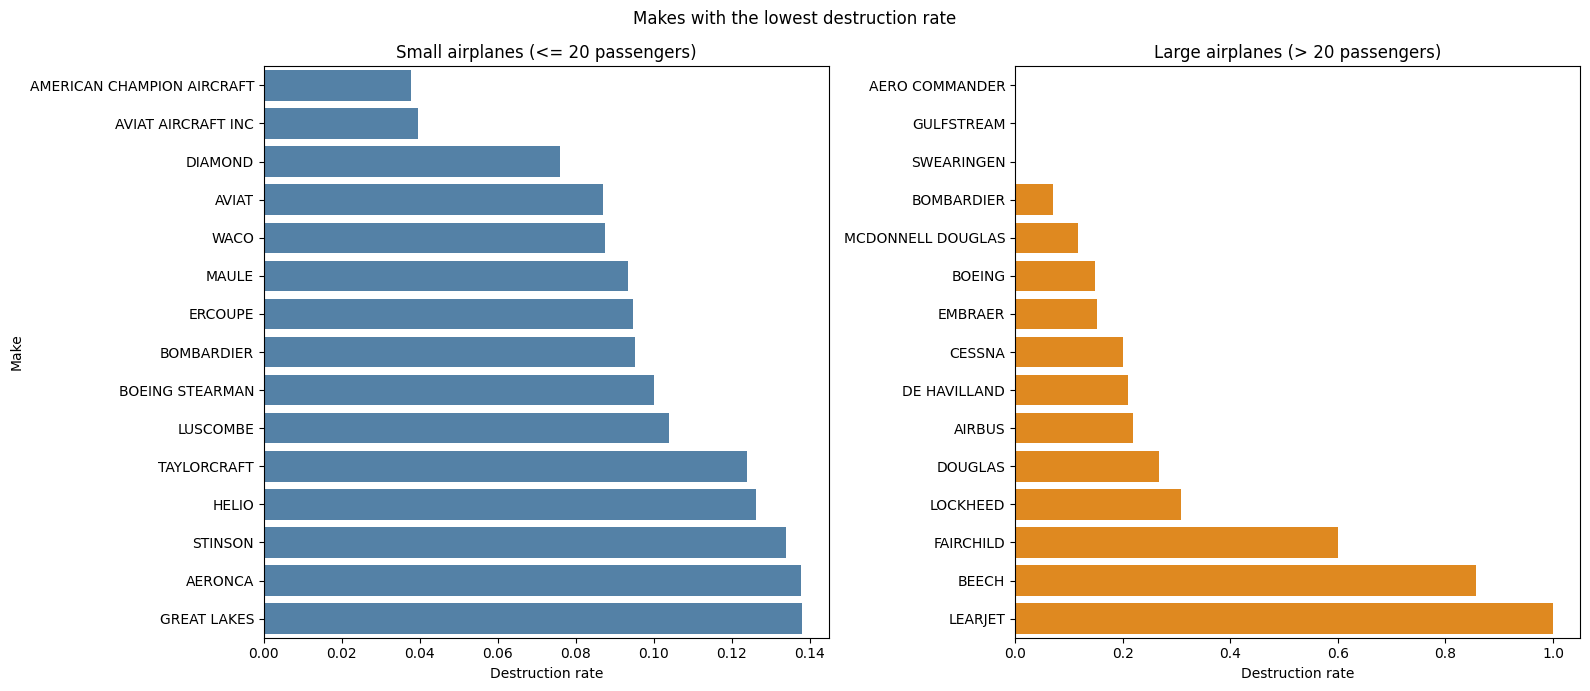

In [13]:
# Destroyed = 1 if the aircraft was destroyed, 0 otherwise
# So the mean of Destroyed per make = destruction rate

# Small airplanes: destruction rate and number of events per make, lowest 15
small_destroyed = small.groupby("Make")["Destroyed"].agg(["mean", "count"])
top15_small_destroyed = small_destroyed.sort_values("mean").head(15)

# Large airplanes: same computation
large_destroyed = large.groupby("Make")["Destroyed"].agg(["mean", "count"])
top15_large_destroyed = large_destroyed.sort_values("mean").head(15)

print("Small makes - lowest destruction rate:")
print(top15_small_destroyed)
print("\nLarge makes - lowest destruction rate:")
print(top15_large_destroyed)

# Side-by-side bar plots of the destruction rate
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Small airplanes
sns.barplot(x=top15_small_destroyed["mean"], y=top15_small_destroyed.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small airplanes (<= 20 passengers)")
axes[0].set_xlabel("Destruction rate")
axes[0].set_ylabel("Make")

# Large airplanes
sns.barplot(x=top15_large_destroyed["mean"], y=top15_large_destroyed.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large airplanes (> 20 passengers)")
axes[1].set_xlabel("Destruction rate")
axes[1].set_ylabel("")

plt.suptitle("Makes with the lowest destruction rate")
plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion of findings: Makes

*Group averages used as a reference*
- Small airplanes (<= 20 passengers): mean fatal/serious injury fraction = 27.3%, destruction rate = 21.1%.
- Large airplanes (> 20 passengers): mean fatal/serious injury fraction = 14.3%, destruction rate = 17.1%.

*Distributions*
- The fatal/serious injury fraction is not spread evenly. Most accidents have a fraction of 0 (no one seriously hurt), and a smaller group has a fraction of 1 (everyone on board seriously hurt or killed). Very few accidents fall in between.
- For all the makes we plotted, the median is 0. This means the mean is pulled up by a small number of very severe accidents.
- The violin plot (small makes) shows that 76% to 87% of accidents for the 10 best makes cause no serious injury or death.
- The strip plot (large makes) shows clearly that some makes have only 1 to 5 accidents (Aero Commander, Gulfstream, Swearingen, Learjet, Cessna). Their low means are not reliable, so we do not recommend them.

*Recommendations: small airplanes*

We recommend makes that are low on *both* measures and have enough accidents to trust the result:

| Make | Accidents | Fatal/serious fraction | Destruction rate |
|---|---|---|---|
| WACO | 137 | 10.3% | 8.8% |
| Maule | 567 | 15.4% | 9.3% |
| Helio | 103 | 13.4% | 12.6% |
| Aviat Aircraft Inc | 76 | 16.4% | 3.9% |
| Great Lakes | 58 | 16.4% | 13.8% |

All five makes are well below the small-airplane average (27.3% injury, 21.1% destruction). Maule is the strongest choice because its result is based on the largest number of accidents (567).

*Recommendations: large airplanes*

| Make | Accidents | Fatal/serious fraction | Destruction rate |
|---|---|---|---|
| McDonnell Douglas | 102 | 6.2% | 11.8% |
| Bombardier | 42 | 8.2% | 7.1% |
| Boeing | 316 | 14.0% | 14.9% |
| Embraer | 46 | 16.1% | 15.2% |

McDonnell Douglas and Bombardier are clearly below the large-airplane average on both measures. Boeing is close to the average for injuries but slightly better on destruction, and it has by far the most data (316 accidents), so its result is the most reliable. Embraer is close to the average.

*Limits*
- The large-airplane group is small (655 accidents in total), so differences between makes should be read with caution.
- These rates describe what happens *once an accident occurs*. They do not measure how often each make has accidents, because we do not have the number of flights or flight hours.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                         mean_fraction  count  destroyed_rate
Make.Model                                                   
MCDONNELL DOUGLAS MD-88       0.004600     12        0.000000
BOMBARDIER CL-600-2B19        0.009489     11        0.000000
BOEING 737-300                0.043406     12        0.166667
BOEING 737                    0.248028     52        0.211538


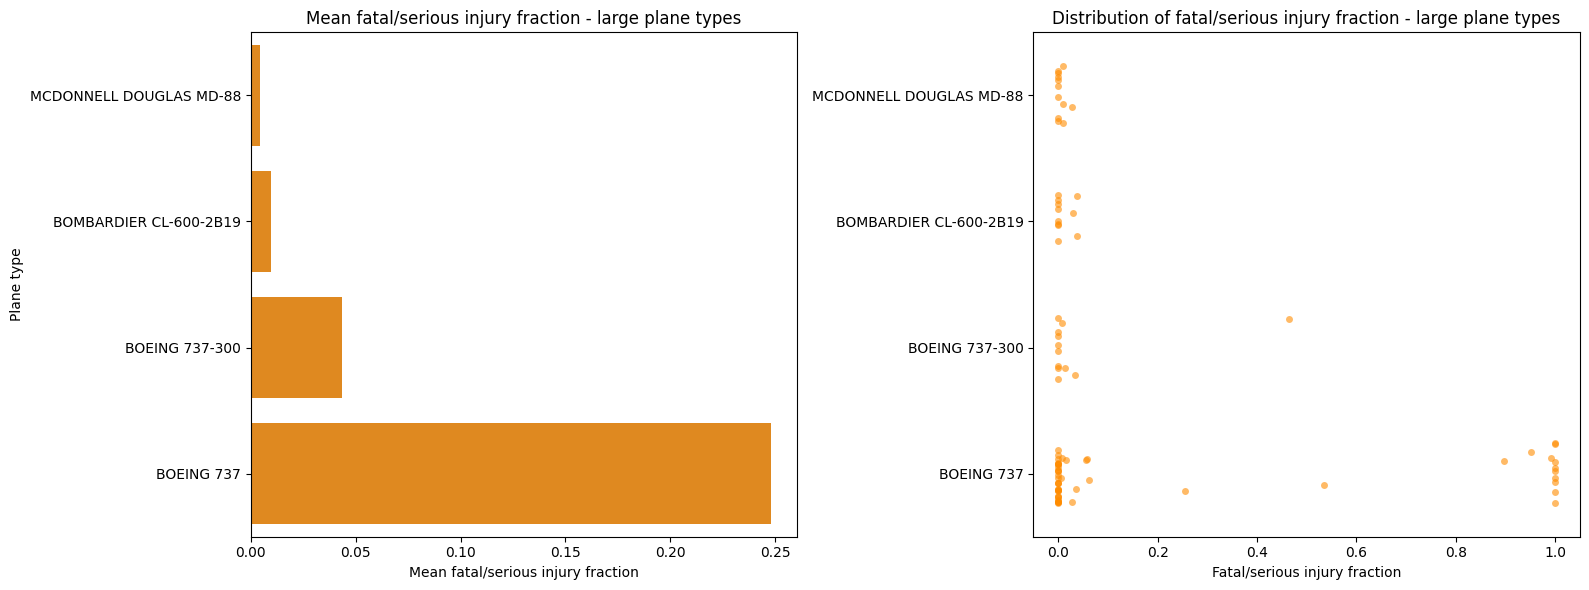

In [14]:
# Minimum number of events per plane type (given in the instructions)
min_events = 10

# Mean fatal/serious fraction, number of events and destruction rate per plane type
large_type = large.groupby("Make.Model").agg(
    mean_fraction=("Fatal.Serious.Fraction", "mean"),
    count=("Fatal.Serious.Fraction", "count"),
    destroyed_rate=("Destroyed", "mean")
)

# Keep plane types with at least 10 events and sort from lowest to highest mean
large_type = large_type[large_type["count"] >= min_events].sort_values("mean_fraction")
print(large_type)

# Keep the events of these plane types for the distribution plot
large_type_data = large[large["Make.Model"].isin(large_type.index)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: mean fatal/serious fraction per plane type
sns.barplot(x=large_type["mean_fraction"], y=large_type.index, ax=axes[0], color="darkorange")
axes[0].set_title("Mean fatal/serious injury fraction - large plane types")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[0].set_ylabel("Plane type")

# Right: distribution of the fraction, each dot is one accident
sns.stripplot(data=large_type_data, x="Fatal.Serious.Fraction", y="Make.Model",
              order=large_type.index, jitter=0.25, alpha=0.6, ax=axes[1], color="darkorange")
axes[1].set_title("Distribution of fatal/serious injury fraction - large plane types")
axes[1].set_xlabel("Fatal/serious injury fraction")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

                      mean_fraction  count  destroyed_rate
Make.Model                                                
AYRES S2R-G10              0.000000     11        0.181818
GRUMMAN G164B              0.000000     18        0.166667
DIAMOND DA 20 C1           0.000000     11        0.000000
PIPER PA-18A 150           0.000000     12        0.000000
CESSNA 180C                0.000000     14        0.071429
MAULE MX-7-235             0.029412     17        0.000000
BEECH 1900D                0.040000     25        0.040000
CESSNA C172                0.041667     12        0.000000
NORTH AMERICAN AT-6G       0.045455     11        0.000000
MAULE M-7-235B             0.050000     10        0.000000


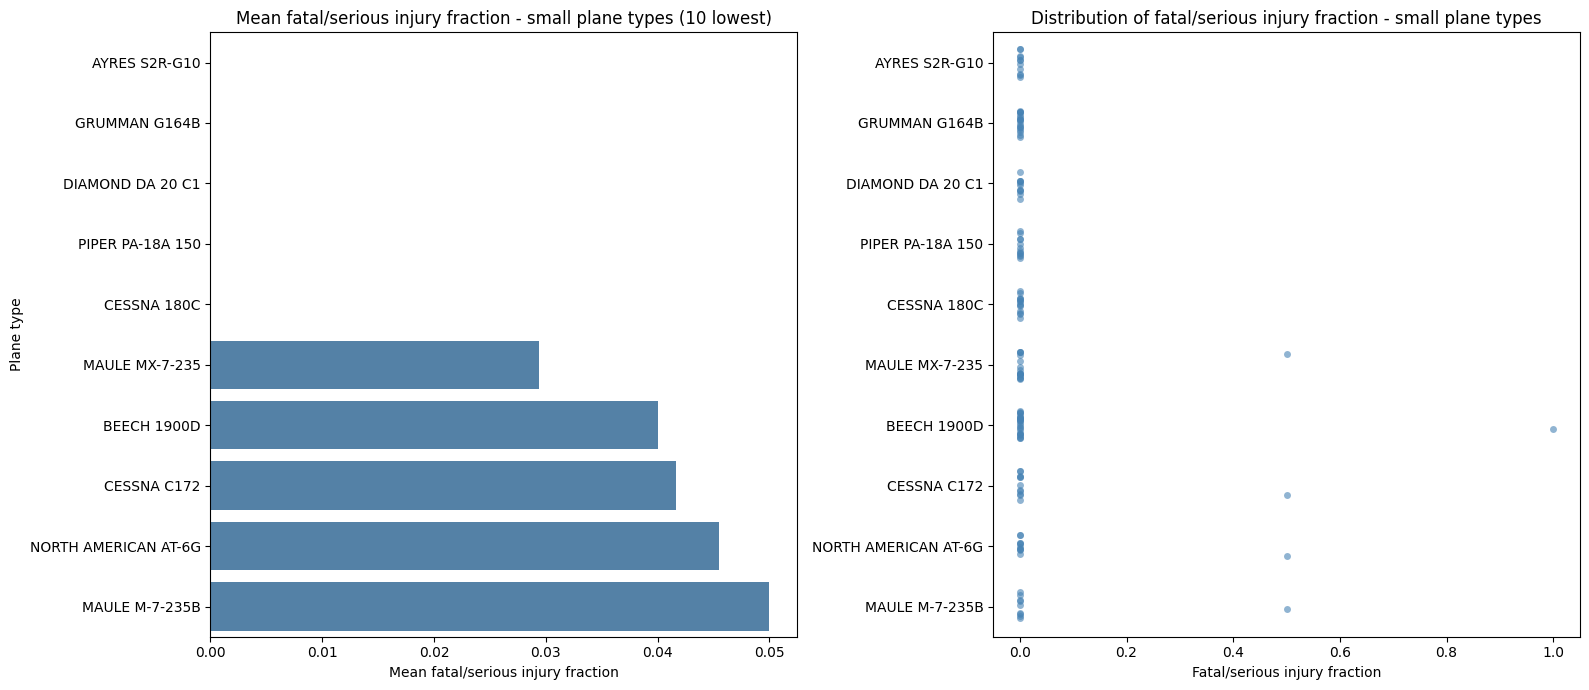

In [15]:
# Mean fatal/serious fraction, number of events and destruction rate per plane type
small_type = small.groupby("Make.Model").agg(
    mean_fraction=("Fatal.Serious.Fraction", "mean"),
    count=("Fatal.Serious.Fraction", "count"),
    destroyed_rate=("Destroyed", "mean")
)

# Keep plane types with at least 10 events, then the 10 with the lowest mean
small_type = small_type[small_type["count"] >= min_events]
top10_small_type = small_type.sort_values("mean_fraction").head(10)
print(top10_small_type)

# Keep the events of these 10 plane types for the distribution plot
small_type_data = small[small["Make.Model"].isin(top10_small_type.index)]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: mean fatal/serious fraction per plane type
sns.barplot(x=top10_small_type["mean_fraction"], y=top10_small_type.index, ax=axes[0], color="steelblue")
axes[0].set_title("Mean fatal/serious injury fraction - small plane types (10 lowest)")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[0].set_ylabel("Plane type")

# Right: distribution of the fraction, each dot is one accident
sns.stripplot(data=small_type_data, x="Fatal.Serious.Fraction", y="Make.Model",
              order=top10_small_type.index, jitter=0.25, alpha=0.6, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of fatal/serious injury fraction - small plane types")
axes[1].set_xlabel("Fatal/serious injury fraction")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types

For large planes, only 4 plane types have at least 10 accidents, so the evidence is limited. The McDonnell Douglas MD-88 (0.5%) and the Bombardier CL-600-2B19 (0.9%) stand out, with almost no serious injuries and no aircraft destroyed. This confirms the make-level results. The Boeing 737-300 also does well (4.3%). The generic "Boeing 737" label, at 24.8%, probably groups older versions and poorly recorded events, so it should not be used to judge modern 737 models.

For small planes, the 10 best plane types are between 0% and 5%, far below the small-airplane average of 27.3%. The Piper PA-18A 150, Diamond DA 20 C1, Maule MX-7-235, Maule M-7-235B, Cessna C172 and Beech 1900D are good on both injuries and destruction. Maule appears twice in the top 10, which confirms it as one of the best small makes. The Beech 1900D is the most reliable result, with 25 accidents. The Ayres S2R-G10 and Grumman G164B protect the people on board but are often destroyed, at about 17% to 18%.

Each plane type has only 10 to 52 accidents, so these results are less robust than the make-level ones. A rate of 0% over 11 accidents means that no severe case was recorded, not that the plane is perfectly safe.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                   events  mean_fraction  destroyed_rate
Weather.Condition                                       
IMC                  4529       0.676989        0.593509
VMC                 50780       0.222820        0.168452


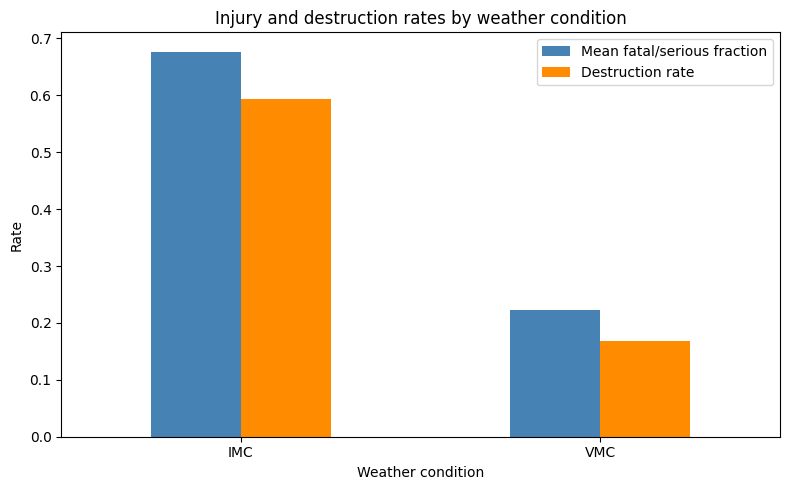

In [16]:
# VMC = good visibility (visual flight), IMC = poor visibility (instrument flight)
# We remove "Unknown" because it does not tell us anything about the weather
weather = df[df["Weather.Condition"] != "Unknown"]

# Number of events, mean fatal/serious fraction and destruction rate per weather condition
weather_stats = weather.groupby("Weather.Condition").agg(
    events=("Destroyed", "count"),
    mean_fraction=("Fatal.Serious.Fraction", "mean"),
    destroyed_rate=("Destroyed", "mean")
)
print(weather_stats)

# Bar plot comparing both measures for VMC and IMC
weather_stats[["mean_fraction", "destroyed_rate"]].plot(kind="bar", figsize=(8, 5), color=["steelblue", "darkorange"])
plt.title("Injury and destruction rates by weather condition")
plt.xlabel("Weather condition")
plt.ylabel("Rate")
plt.xticks(rotation=0)
plt.legend(["Mean fatal/serious fraction", "Destruction rate"])
plt.tight_layout()
plt.show()

### Weather Condition

Weather has a strong link with the outcome of an accident. In good visibility (VMC, 50,780 accidents), the mean fatal/serious fraction is 22.3% and 16.8% of aircraft are destroyed. In poor visibility (IMC, 4,529 accidents), these numbers jump to 67.7% and 59.4%. So an accident in IMC is about three times more likely to be severe and to destroy the aircraft. Both groups have thousands of accidents, so this difference is robust and not the result of a few unusual cases. For the client, flights in poor visibility are a clear risk factor, and pilot instrument training should be taken into account.

                       events  mean_fraction  destroyed_rate
Broad.phase.of.flight                                       
Taxi                     1399       0.017490        0.023588
Landing                 11729       0.035475        0.043823
Standing                  471       0.087096        0.135881
Takeoff                  8732       0.230344        0.223431
Go-around                1156       0.300815        0.288927
Descent                  1214       0.352305        0.337727
Cruise                   6986       0.357606        0.348841
Approach                 4471       0.358189        0.304630
Climb                    1365       0.441679        0.443956
Maneuvering              4676       0.529870        0.474337


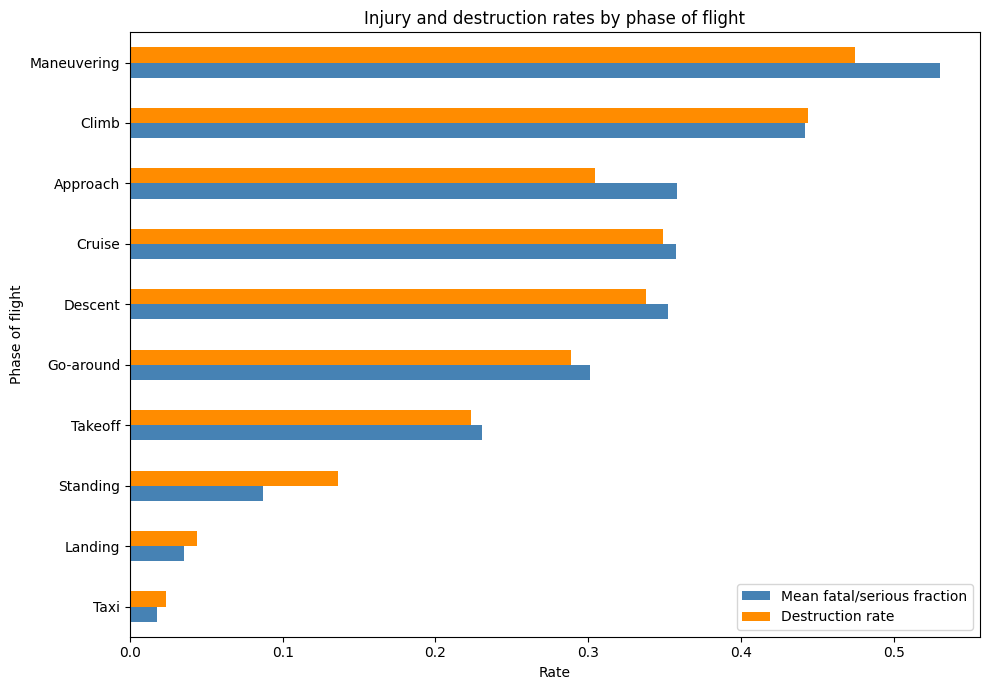

In [18]:
# We remove "Unknown" and "Other" because they do not describe a real phase of flight
phase = df[~df["Broad.phase.of.flight"].isin(["Unknown", "Other"])]

# Number of events, mean fatal/serious fraction and destruction rate per phase
phase_stats = phase.groupby("Broad.phase.of.flight").agg(
    events=("Destroyed", "count"),
    mean_fraction=("Fatal.Serious.Fraction", "mean"),
    destroyed_rate=("Destroyed", "mean")
).sort_values("mean_fraction")
print(phase_stats)

# Bar plot comparing both measures for each phase, sorted from safest to most severe
phase_stats[["mean_fraction", "destroyed_rate"]].plot(kind="barh", figsize=(10, 7), color=["steelblue", "darkorange"])
plt.title("Injury and destruction rates by phase of flight")
plt.xlabel("Rate")
plt.ylabel("Phase of flight")
plt.legend(["Mean fatal/serious fraction", "Destruction rate"])
plt.tight_layout()
plt.show()

## Phase of Flight

The phase of flight also changes how severe an accident is. Accidents on the ground or at low speed are the least severe: taxi (1.7% fatal/serious, 2.4% destroyed) and landing (3.5% and 4.4%). Landing is one of the most common phases, with 11,729 accidents, but these accidents are rarely serious. On the other side, maneuvering is the most dangerous phase, with 53.0% fatal/serious and 47.4% destroyed, followed by climb (44.2% and 44.4%), then approach, cruise and descent (all around 35%). In these phases the aircraft is high and fast, so a loss of control has heavier consequences. Every phase except standing has more than 1,000 accidents, so these results are robust. For the client, the risk is not only how often a phase has accidents, but how severe they are: landing accidents are frequent but mild, while maneuvering and climb accidents are less frequent but much more severe.